# Survey ways to plot cross sections with OpenMC

<!-- index:description -->
Survey three ways to plot continuous-energy cross sections in OpenMC: `plot_xs()`, `calculate_cexs()`, and direct access to HDF5 data.
<!-- /index:description -->

<!-- generated:structure -->
```text
Survey ways to plot cross sections with OpenMC
├── 1. `openmc.plot_xs()`
├── 2. `openmc.calculate_cexs()`
└── 3. `openmc.data.IncidentNeutron.from_hdf5()`
    ├── Inspect `xs_data`
    └── Extract barns from `xs_data`
```
<!-- /generated:structure -->

Plot triton-production cross sections (MT=205, (n,Xt)) of Li6 and Li7 using the same ENDF/B-VIII.1 library at 294 K. The three approaches differ mainly in how much control they give over the data and plotting.

In [1]:
import openmc
import numpy as np
import matplotlib.pyplot as plt
from openmc_workbench_config import DATA_ROOT

xs_xml = DATA_ROOT / 'endf-b8.1' / 'cross_sections.xml'
openmc.config['cross_sections'] = xs_xml

# Li6: Higher (n,t) cross section at thermal neutron energies.
# Li7: 92.4% natural abundance; tritium production above ~2.5 MeV.
nuclides = ['Li6', 'Li7']

temperature_K = 294

# Reference energies (MeV): thermal neutrons (~0.025 eV)
# and D-T fusion neutrons (~14 MeV).
energies_MeV = [0.025e-6, 14]

mt, mt_label = 205, '(n,Xt)'
reactions = {nuclide: [mt_label] for nuclide in nuclides}

def format_ax(ax):
    for E in energies_MeV:
        ax.axvline(E, ls=':', color='k')
    ax.grid()
    ax.set(
        xscale='log',
        yscale='log',
        xlabel='Energy (MeV)',
        ylabel='Microscopic cross section (b)',
    )
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))

## 1. `openmc.plot_xs()`

The shortest route: OpenMC calculates and plots the cross sections. Matplotlib can still be used to customize the axes.

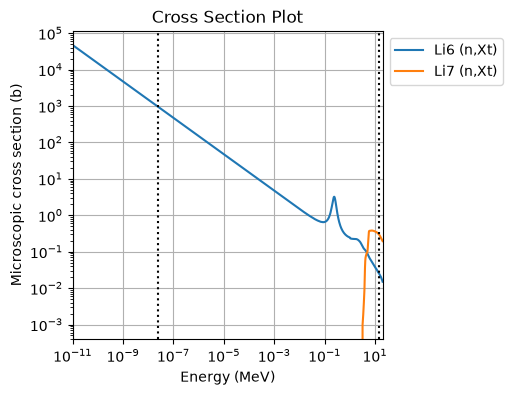

In [2]:
fig, ax = plt.subplots(figsize=(4, 4))
openmc.plot_xs(
    reactions = reactions,
    temperature = temperature_K,
    energy_axis_units = 'MeV',
    axis = ax
)
format_ax(ax)
# Plot explains the motivation behind lithium enrichment.

## 2. `openmc.calculate_cexs()`
Obtain the energy grid (in eV) and cross-section arrays (in barns), then plot them yourself with Matplotlib.

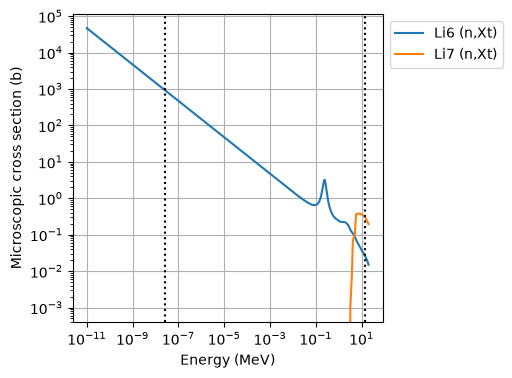

In [3]:
fig, ax = plt.subplots(figsize=(4, 4))

for nuclide, types in reactions.items():
    E, xs = openmc.plotter.calculate_cexs(
        nuclide, types, temperature=temperature_K
    )
    for reaction, values in zip(types, xs):
        ax.plot(E / 1e6, values, label=f'{nuclide} {reaction}')

format_ax(ax)

## 3. `openmc.data.IncidentNeutron.from_hdf5()`
Read the tabulated cross sections directly from the HDF5 library. Here, each reaction's xs is an openmc.data.Tabulated1D object. Unlike the preceding approaches, the temperature entry is selected explicitly.

Function returns an [openmc.data.Tabulated1D](https://docs.openmc.org/en/stable/pythonapi/generated/openmc.data.Tabulated1D.html) object.

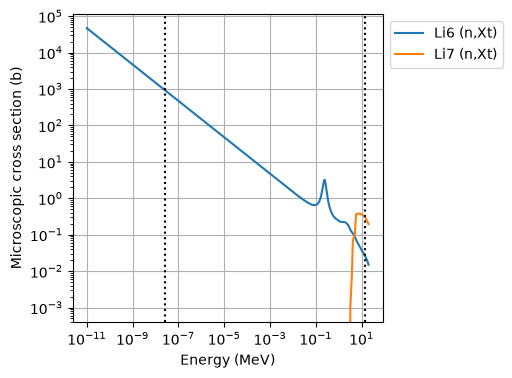

In [4]:
library = openmc.data.DataLibrary.from_xml()

xs_data = {}
fig, ax = plt.subplots(figsize=(4, 4))
for nuclide in nuclides:
    filename = library.get_by_material(nuclide)['path']
    data = openmc.data.IncidentNeutron.from_hdf5(filename)

    xs_data[nuclide] = data[mt].xs[f'{temperature_K}K']
    E = xs_data[nuclide].x
    xs = xs_data[nuclide].y
    ax.plot(E / 1e6, xs, label=f'{nuclide} {mt_label}')

format_ax(ax)

### Inspect `xs_data`
The following cells examine `xs_data` from the last iteration above (Li7):
- `interpolation` gives the interpolation codes;
- `breakpoints` marks the ends of interpolation regions.

In [5]:
xs_data['Li6'].interpolation
# That's the linear-linear interpolation scheme

array([2])

In [6]:
from openmc.data.function import INTERPOLATION_SCHEME
INTERPOLATION_SCHEME

{1: 'histogram',
 2: 'linear-linear',
 3: 'linear-log',
 4: 'log-linear',
 5: 'log-log'}

In [7]:
xs_data['Li6'].breakpoints

array([865])

### Extract barns from `xs_data`
A Tabulated1D object can be called like a function. The input energy is in eV; the returned cross section is in barns.

In [8]:
xs_data['Li6'](np.asarray(energies_MeV)*1e6)
# barns at 0.025e-6 MeV and 14 MeV

array([9.43733919e+02, 2.60000000e-02])